Best path: A -> B -> D -> C -> A
Minimum cost: 23


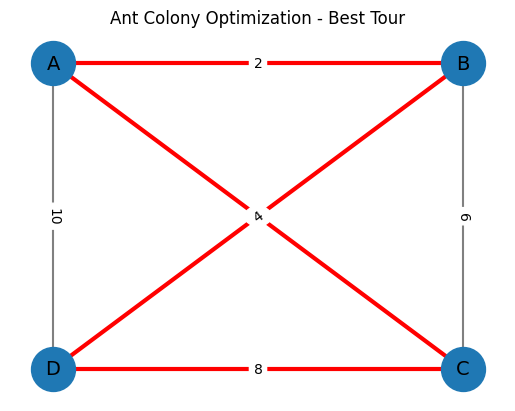

In [1]:

import random
import networkx as nx
import matplotlib.pyplot as plt

# Distance matrix
distance = [
    [0, 2, 9, 10],
    [2, 0, 6, 4],
    [9, 6, 0, 8],
    [10, 4, 8, 0]
]

n = len(distance)
ants = 4
iterations = 20

alpha = 1
beta = 2
rho = 0.5
Q = 100

# Initialize pheromones
pheromone = [[1.0] * n for _ in range(n)]

best_path = None
best_cost = float('inf')

# ACO algorithm
for iteration in range(iterations):

    for ant in range(ants):

        start = random.randint(0, n - 1)
        path = [start]
        unvisited = list(range(n))
        unvisited.remove(start)

        # Select the next city
        while unvisited:
            current = path[-1]
            probabilities = []

            for city in unvisited:
                p = pheromone[current][city] ** alpha
                h = (1 / distance[current][city]) ** beta
                probabilities.append(p * h)

            total = sum(probabilities)
            probabilities = [p / total for p in probabilities]

            next_city = random.choices(
                unvisited, weights=probabilities, k=1
            )[0]

            path.append(next_city)
            unvisited.remove(next_city)

        # Calculate tour cost
        cost = sum(
            distance[path[i]][path[i + 1]]
            for i in range(n - 1)
        )
        cost += distance[path[-1]][path[0]]

        # Store the best path
        if cost < best_cost:
            best_cost = cost
            best_path = path[:]

        # Evaporate pheromones
        for i in range(n):
            for j in range(n):
                pheromone[i][j] *= (1 - rho)

        # Deposit pheromones
        for i in range(n):
            a = path[i]
            b = path[(i + 1) % n]

            pheromone[a][b] += Q / cost
            pheromone[b][a] += Q / cost

# Print result
cities = ['A', 'B', 'C', 'D']
best_tour = [cities[i] for i in best_path]
best_tour.append(best_tour[0])

print("Best path:", " -> ".join(best_tour))
print("Minimum cost:", best_cost)

# Create graph
G = nx.Graph()

for i in range(n):
    for j in range(i + 1, n):
        G.add_edge(cities[i], cities[j],
                   weight=distance[i][j])

# Draw graph
pos = {
    'A': (0, 1),
    'B': (2, 1),
    'C': (2, -1),
    'D': (0, -1)
}

best_edges = [
    (cities[best_path[i]],
     cities[best_path[(i + 1) % n]])
    for i in range(n)
]

nx.draw_networkx_nodes(
    G, pos, node_size=1000
)
nx.draw_networkx_labels(
    G, pos, font_size=14
)

# Draw all edges
nx.draw_networkx_edges(
    G, pos, edge_color='gray', width=1.5
)

# Highlight best tour
nx.draw_networkx_edges(
    G, pos, edgelist=best_edges,
    edge_color='red', width=3
)

edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(
    G, pos, edge_labels=edge_labels
)

plt.title("Ant Colony Optimization - Best Tour")
plt.axis('off')
plt.show()


# Nisha 1WN24CS183